# Notebook 02 — Modeling and Evaluation
**Task:** predict Remaining Useful Life (cycles) of aircraft engines (NASA C-MAPSS FD001).

**Plan**
1. Load the cleaned data (from Notebook 01) and define features, target and engine groups.
2. Split the engines with a fixed random seed and compare five models.
3. Compare the models with grouped 5-fold cross-validation.
4. Tune Ridge, Lasso, Random Forest and Gradient Boosting.
5. Evaluate every final model on the **official NASA test set** (the last observed cycle of 100 unseen engines).
6. Save all models (each one is a pipeline that includes its own preprocessing).

All scaling is done *inside* the pipelines, so nothing is fitted before splitting (no data leakage).

**Training target.** Following Notebook 01 (section 9) the models learn `min(RUL, 125)`. Scores on the training side (hold-out split, cross-validation) are measured against that same capped target, because the sensors carry no signal about RUL above ~125. Scores on the **official NASA test set are always measured against the real RUL**.

## 1. Load data and define features, target and groups

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    GroupShuffleSplit,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sys.path.append("..")
from Helper.helper import MODEL_FILES, RUL_CAP, evaluate, last_cycle_rows, load_cmapss

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
IMAGES = Path("../Images")
MODELS_DIR = Path("../Models")
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_csv("../Data/Cleaned/train_FD001_cleaned.csv")

X = df.drop(columns=["RUL", "engine_id"])     # engine_id identifies the engine, it is not a feature
y = df["RUL"]
groups = df["engine_id"]
y_cap = y.clip(upper=RUL_CAP)          # training target: min(RUL, 125), see Notebook 01 section 9

print("Features:", X.shape[1], "| Rows:", len(X), "| Engines:", groups.nunique())
print("Rows whose target is capped:", int((y > RUL_CAP).sum()), f"({(y > RUL_CAP).mean():.0%})")
print(list(X.columns))

Features: 18 | Rows: 20631 | Engines: 100
Rows whose target is capped: 8031 (39%)
['cycle', 'setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


**Why engines are grouped.** Rows from the same engine are strongly dependent. If one engine appeared in both the training and the validation part, the model would see almost the same data twice and the scores would look better than they really are. Every split below therefore keeps all rows of an engine together.

## 2. Model definitions

In [2]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "Lasso": Pipeline([                                   # contributed by our Part 2 teammate
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, max_iter=50000)),
    ]),
    "Random Forest": Pipeline([
        ("model", RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                        random_state=SEED, n_jobs=-1)),
    ]),
    "Gradient Boosting": Pipeline([
        ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1,
                                            max_depth=3, random_state=SEED)),
    ]),
}
list(models)

['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']

The two linear models get a `StandardScaler` because their coefficients depend on feature scale. The two tree-based models split on thresholds, so scaling does not change them and is skipped.

## 3. Train / validation split (fixed seed) and baseline comparison
We hold out 20% of the **engines** (20 engines) as a validation set, using `random_state=42`.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(X, y, groups))

X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_tr, y_val = y_cap.iloc[train_idx], y_cap.iloc[val_idx]
print("Train engines:", groups.iloc[train_idx].nunique(), "| Validation engines:", groups.iloc[val_idx].nunique())
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[val_idx]))

rows = []
for name, model in models.items():
    m = clone(model).fit(X_tr, y_tr)
    rows.append({"Model": name, **evaluate(y_val, m.predict(X_val))})

holdout_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
holdout_df.round(3)

Train engines: 80 | Validation engines: 20


,Model,MAE,RMSE,R²
0,Gradient Boosting,10.826,15.564,0.861
1,Random Forest,10.863,16.021,0.853
2,Linear Regression,14.477,17.902,0.816
3,Ridge,14.477,17.902,0.816
4,Lasso,14.494,17.913,0.816


## 4. Grouped 5-fold cross-validation

In [4]:
cv = GroupKFold(n_splits=5)
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}

rows = []
for name, model in models.items():
    s = cross_validate(model, X, y_cap, groups=groups, cv=cv, scoring=scoring, n_jobs=-1, error_score="raise")
    rows.append({
        "Model": name,
        "MAE": -s["test_MAE"].mean(),
        "RMSE": -s["test_RMSE"].mean(),
        "R²": s["test_R2"].mean(),
        "RMSE std": s["test_RMSE"].std(),
    })

cv_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
cv_df.round(3)

,Model,MAE,RMSE,R²,RMSE std
0,Gradient Boosting,11.545,16.555,0.842,0.747
1,Random Forest,11.487,16.764,0.838,0.713
2,Ridge,16.332,20.095,0.766,1.383
3,Linear Regression,16.332,20.095,0.766,1.383
4,Lasso,16.336,20.095,0.766,1.381


**Conclusion.** Gradient Boosting is best in cross-validation (RMSE 16.56, R² 0.842), with Random Forest practically tied (RMSE 16.76) and both clearly ahead of the three linear models, which are indistinguishable from each other (RMSE 20.10). These errors are measured against the capped target `min(RUL, 125)`. Ridge and Lasso with their default alphas are identical to plain Linear Regression because 18 standardised features and 20,000 rows leave almost nothing to shrink. The single 20-engine split in section 3 gave a slightly better R² (0.861 for Gradient Boosting) than the 5-fold average (0.842): one split depends on which engines happen to be in it, which is why we select models with cross-validation.

## 5. Hyperparameter tuning (grouped cross-validation)
Four models are tuned with `GridSearchCV`. The best setting is chosen by mean validation **RMSE** and the grouped folds are the same as above.

In [5]:
param_grids = {
    "Ridge": {"model__alpha": [0.1, 1, 10, 100, 1000]},
    "Lasso": {"model__alpha": [0.001, 0.01, 0.1, 1, 10]},
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [10, None],
        "model__min_samples_leaf": [2, 5, 10],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 4],
    },
}

searches = {}
tuning_rows = []
for name, grid in param_grids.items():
    print("Tuning:", name)
    search = GridSearchCV(models[name], grid, scoring=scoring, refit="RMSE",
                          cv=cv, n_jobs=-1, error_score="raise")
    search.fit(X, y_cap, groups=groups)
    searches[name] = search
    best = search.best_index_
    tuning_rows.append({
        "Model": name,
        "Best parameters": search.best_params_,
        "CV MAE": -search.cv_results_["mean_test_MAE"][best],
        "CV RMSE": -search.cv_results_["mean_test_RMSE"][best],
        "CV R²": search.cv_results_["mean_test_R2"][best],
    })

tuning_df = pd.DataFrame(tuning_rows)
pd.set_option("display.max_colwidth", None)
tuning_df.round(3)

Tuning: Ridge


Tuning: Lasso


Tuning: Random Forest


Tuning: Gradient Boosting


,Model,Best parameters,CV MAE,CV RMSE,CV R²
0,Ridge,{'model__alpha': 100},16.337,20.095,0.766
1,Lasso,{'model__alpha': 0.01},16.333,20.095,0.766
2,Random Forest,"{'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}",11.408,16.649,0.840
3,Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}",11.451,16.506,0.843


**Conclusion.** Tuning helped only a little, which means the default settings were already close to optimal: Gradient Boosting improved its CV RMSE from 16.56 to 16.51 (200 trees, learning rate 0.1, depth 3), Random Forest from 16.76 to 16.65 (200 trees, unlimited depth, `min_samples_leaf=10`), and neither Ridge (`alpha=100`) nor Lasso (`alpha=0.01`) changed at all (CV RMSE 20.10 for both). After tuning, Gradient Boosting still has the lowest CV RMSE and remains the leading candidate.

## 6. Official test set
NASA provides separate test engines that stop *before* failure and a file with the true RUL at their last observed cycle. As in the NASA protocol, we predict from the **last observed row of each of the 100 test engines**. This data was never used for training or tuning.

In [6]:
test_df = load_cmapss("../Data/Original/test_FD001.txt")
y_test = pd.read_csv("../Data/Original/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])["RUL"]

test_last = last_cycle_rows(test_df)
X_test = test_last[X.columns].copy()

assert len(X_test) == len(y_test) == 100
print("Test engines:", len(X_test))
X_test.head()

Test engines: 100


,cycle,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,31,-0.0006,0.0004,642.58,1581.22,1398.91,21.61,554.42,2388.08,9056.40,47.23,521.79,2388.06,8130.11,8.4024,393,38.81,23.3552
1,49,0.0018,-0.0001,642.55,1586.59,1410.83,21.61,553.52,2388.10,9044.77,47.67,521.74,2388.09,8126.90,8.4505,391,38.81,23.2618
2,126,-0.0016,0.0004,642.88,1589.75,1418.89,21.61,552.59,2388.16,9049.26,47.88,520.83,2388.14,8131.46,8.4119,395,38.93,23.2740
3,106,0.0012,0.0004,642.78,1594.53,1406.88,21.61,552.64,2388.13,9051.30,47.65,521.88,2388.11,8133.64,8.4634,395,38.58,23.2581
4,98,-0.0013,-0.0004,642.27,1589.94,1419.36,21.61,553.29,2388.10,9053.99,47.46,521.00,2388.15,8125.74,8.4362,394,38.75,23.4117


## 7. Final models: fit on all training engines and evaluate on the test set

In [7]:
final_models = {name: clone(model) for name, model in models.items()}
for name, search in searches.items():
    final_models[name] = clone(search.best_estimator_)      # tuned settings, refit below on all data

test_predictions, rows = {}, []
for name, model in final_models.items():
    model.fit(X, y_cap)
    pred = model.predict(X_test)
    test_predictions[name] = pred
    rows.append({"Model": name, **evaluate(y_test, pred)})

test_results_df = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
test_results_df.round(3)

,Model,MAE,RMSE,R²
0,Gradient Boosting,13.048,17.725,0.818
1,Random Forest,13.711,18.295,0.806
2,Ridge,17.780,22.545,0.706
3,Linear Regression,17.786,22.554,0.705
4,Lasso,17.789,22.556,0.705


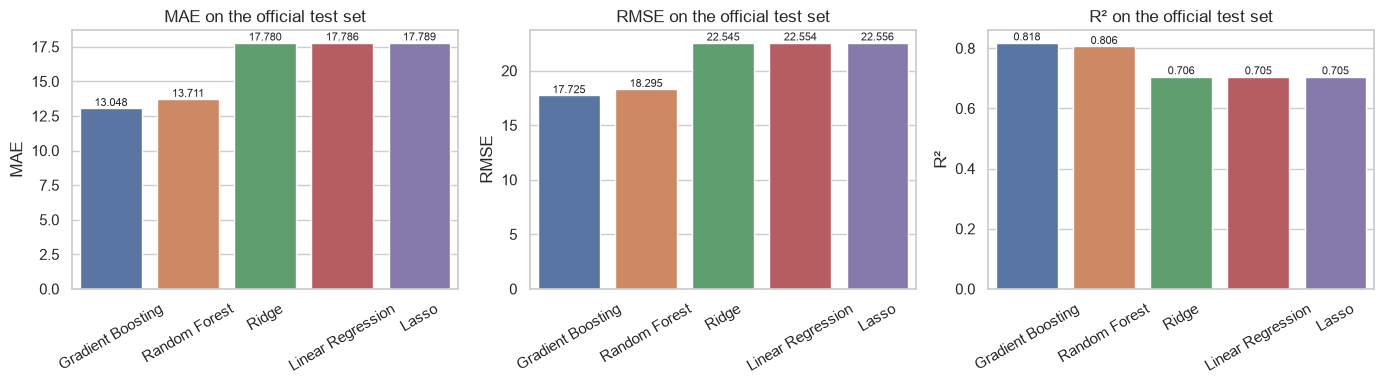

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    sns.barplot(data=test_results_df, x="Model", y=metric, ax=ax, hue="Model", legend=False)
    ax.set_title(f"{metric} on the official test set")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES / "model_comparison.png", dpi=150)
plt.show()

**Conclusion.** Gradient Boosting is the best model on all three metrics on the official NASA test set (MAE 13.05 cycles, RMSE 17.73 cycles, R² 0.818). Random Forest is close (MAE 13.71, RMSE 18.30, R² 0.806) and the three linear models are clearly behind and almost identical to each other (MAE about 17.8, RMSE 22.5, R² 0.705). The tree models reduce RMSE by about 21% compared with Linear Regression, because the sensor-to-RUL relationship is non-linear. A bootstrap over the 100 test engines puts the Gradient Boosting MAE between about 10.7 and 15.4 cycles, so the gap to Random Forest (0.66 cycles) is within the noise; we choose Gradient Boosting because it also won cross-validation. The test R² (0.818) is close to the CV R² (0.842), a sign that model selection did not overfit.

## 8. Actual vs predicted for every model
Each panel plots the predicted RUL of one model against the real RUL of the 100 NASA test engines. Points on the dashed line would be perfect predictions. (Plotting every model separately, and adding Lasso, are ideas from our Part 2 teammate's own notebook.)

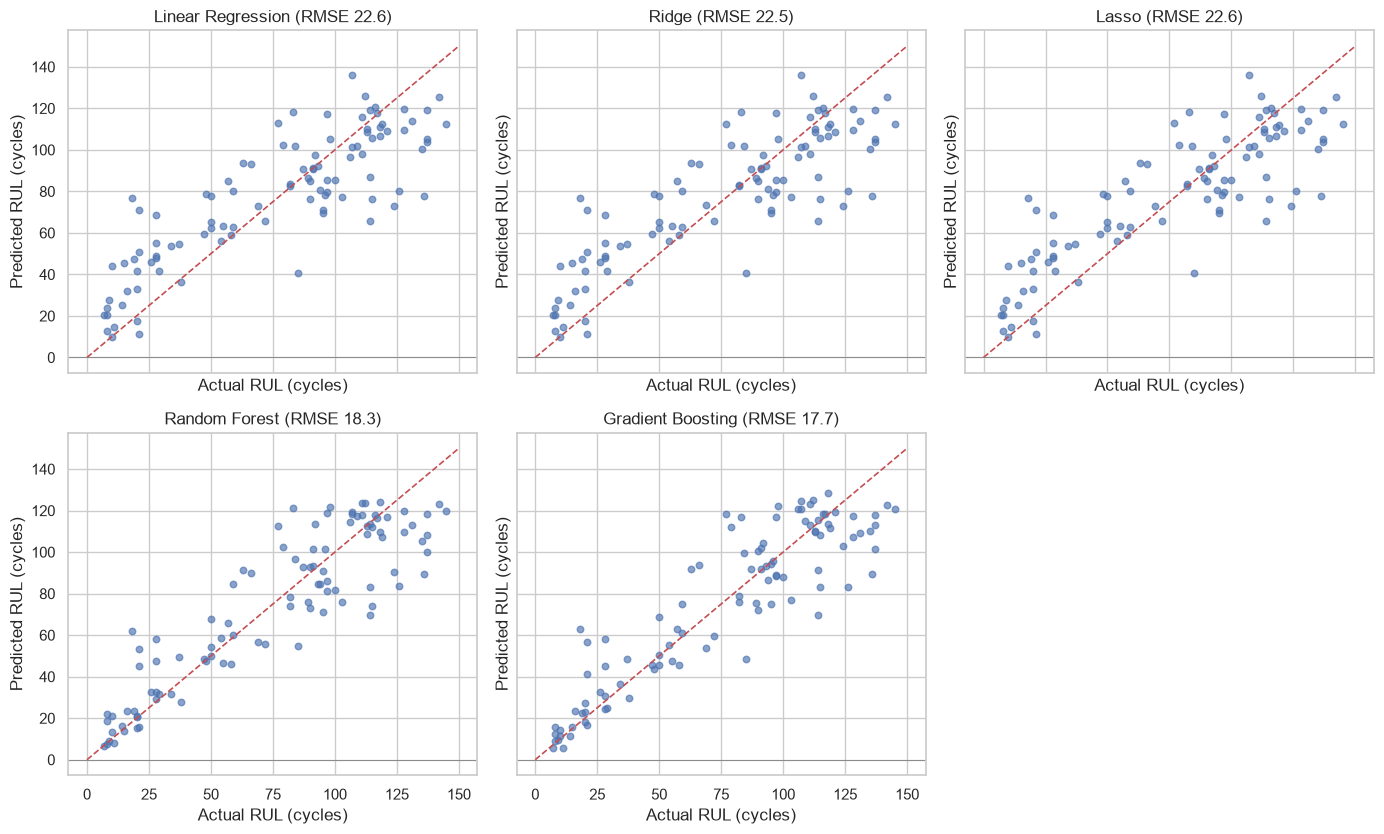

Predictions below zero (physically impossible): {'Linear Regression': 0, 'Ridge': 0, 'Lasso': 0, 'Random Forest': 0, 'Gradient Boosting': 0}


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes.flatten(), test_predictions.items()):
    ax.scatter(y_test, pred, alpha=0.65, s=22)
    ax.plot([0, 150], [0, 150], "r--", linewidth=1.2)
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set_title(f"{name} (RMSE {evaluate(y_test, pred)['RMSE']:.1f})")
    ax.set_xlabel("Actual RUL (cycles)"); ax.set_ylabel("Predicted RUL (cycles)")
for ax in axes.flatten()[len(test_predictions):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(IMAGES / "actual_vs_predicted_all_models.png", dpi=130)
plt.show()

negatives = {name: int((pred < 0).sum()) for name, pred in test_predictions.items()}
print("Predictions below zero (physically impossible):", negatives)

**Conclusion.** The three linear models (Linear Regression, Ridge and Lasso) give almost the same picture: a straight-line fit that overestimates engines close to failure (on average +20 cycles when the real RUL is 30 or less), underestimates engines with more than 100 cycles left (about −16 cycles), and never predicts below about 10 cycles. The tree models hug the diagonal much more closely: near failure their bias is only about +7 to +8 cycles, although they also underestimate the engines above 100 cycles (about −11 to −13). No model predicts a negative life, because the training target never goes below zero.

In [10]:
lasso_coefs = final_models["Lasso"].named_steps["model"].coef_
print("Lasso alpha:", final_models["Lasso"].named_steps["model"].alpha)
print("Features whose coefficient was shrunk to exactly zero:", int((lasso_coefs == 0).sum()), "of", len(lasso_coefs))
print(pd.Series(lasso_coefs, index=X.columns).round(2).sort_values().to_string())

Lasso alpha: 0.01
Features whose coefficient was shrunk to exactly zero: 0 of 18
cycle       -11.44
sensor_11    -4.55
sensor_9     -4.40
sensor_14    -3.16
sensor_4     -2.99
sensor_15    -2.68
sensor_2     -1.97
sensor_13    -1.61
sensor_8     -1.55
sensor_17    -1.44
sensor_3     -1.29
setting_1    -0.12
setting_2     0.18
sensor_6      1.00
sensor_21     1.68
sensor_20     1.74
sensor_7      3.17
sensor_12     3.81


**Conclusion.** Lasso, with the alpha chosen by cross-validation (0.01), shrinks **none** of the 18 coefficients to zero and performs exactly like Linear Regression and Ridge (test RMSE 22.6). So no input is useless for a linear model, and what limits the linear models is their straight-line shape, not over-fitting. Because many sensors are strongly correlated with each other, the individual coefficients share weight and should not be over-interpreted one by one.

## 9. The best model: errors by RUL range, and what it relies on

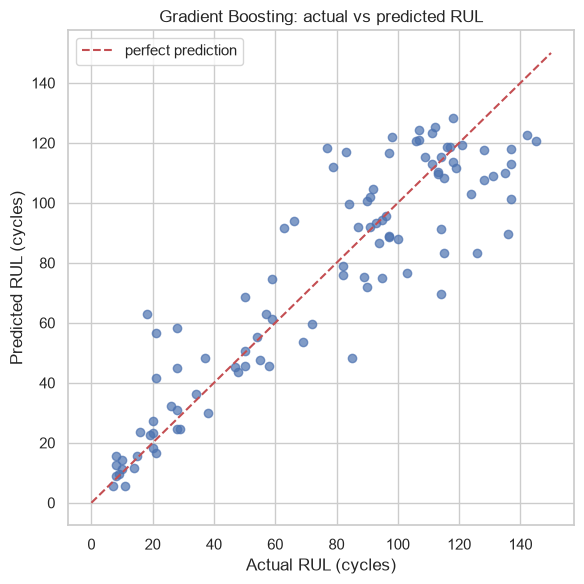

Mean error (bias): -0.7 cycles
Late predictions (model overestimates RUL): 51 of 100 engines


In [11]:
best_name = test_results_df.loc[0, "Model"]
pred = test_predictions[best_name]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, pred, alpha=0.7)
lim = [0, max(y_test.max(), pred.max()) + 5]
ax.plot(lim, lim, "r--", label="perfect prediction")
ax.set_xlabel("Actual RUL (cycles)")
ax.set_ylabel("Predicted RUL (cycles)")
ax.set_title(f"{best_name}: actual vs predicted RUL")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES / "actual_vs_predicted.png", dpi=150)
plt.show()

errors = pred - y_test
print(f"Mean error (bias): {errors.mean():.1f} cycles")
print(f"Late predictions (model overestimates RUL): {(errors > 0).sum()} of {len(errors)} engines")

**Conclusion.** The predictions follow the diagonal. Overall there is no systematic bias (average error −0.7 cycles, with 51 of 100 engines overestimated). Near failure the model leans late: among the 25 engines with a real RUL of 30 cycles or less, 18 are overestimated (average +7 cycles, MAE 8.9), which in practice could delay maintenance. The largest errors are in the middle and upper range (MAE about 15 to 17 cycles). Predictions saturate near 125 (the largest is 128), so engines whose real RUL is above 125 are underestimated (average −11 cycles in the 100 to 145 band); this is the price of the cap.

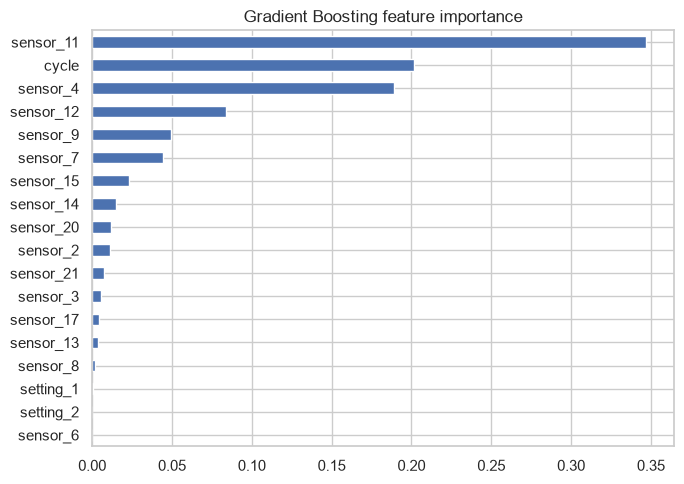

sensor_11    0.347
cycle        0.201
sensor_4     0.189
sensor_12    0.084
sensor_9     0.050
sensor_7     0.045
dtype: float64

In [12]:
gb = final_models["Gradient Boosting"].named_steps["model"]
importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
importance.plot.barh(ax=ax)
ax.set_title("Gradient Boosting feature importance")
fig.tight_layout()
fig.savefig(IMAGES / "feature_importance.png", dpi=150)
plt.show()
importance.sort_values(ascending=False).head(6).round(3)

**Conclusion.** With the capped target the model relies mostly on the sensors: `sensor_11` carries about 35% of the decision, `cycle` about 20% and `sensor_4` about 19%, followed by `sensor_12`. The operating settings contribute almost nothing, which matches their near-zero correlation in Notebook 01. This is healthier than a model that leans on `cycle` alone, because the sensors are what actually change as an engine wears out.

## 10. Ablation: what does the cap buy?
The same tuned pipelines are refitted on the **real** RUL and scored on the same NASA test engines against the real RUL. The PHM08 score is NASA's asymmetric metric used with this data set: predicting a failure too late is punished harder than too early (lower is better).

In [13]:
def phm08(true, pred):
    d = np.asarray(pred) - np.asarray(true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

rows = []
for name in models:
    capped_pred = test_predictions[name]
    real_model = clone(final_models[name]).fit(X, y)             # trained on the real, uncapped RUL
    real_pred = real_model.predict(X_test)
    rows.append({
        "Model": name,
        "RMSE (trained on min(RUL,125))": evaluate(y_test, capped_pred)["RMSE"],
        "RMSE (trained on real RUL)": evaluate(y_test, real_pred)["RMSE"],
        "PHM08 (capped)": phm08(y_test, capped_pred),
        "PHM08 (real)": phm08(y_test, real_pred),
    })
ablation_df = pd.DataFrame(rows).sort_values("RMSE (trained on min(RUL,125))").reset_index(drop=True)
ablation_df.round(2)

,Model,"RMSE (trained on min(RUL,125))",RMSE (trained on real RUL),PHM08 (capped),PHM08 (real)
0,Gradient Boosting,17.72,25.60,575.14,5724.55
1,Random Forest,18.30,25.82,568.79,8158.58
2,Ridge,22.54,31.21,1299.50,6977.30
3,Linear Regression,22.55,31.25,1302.15,6993.83
4,Lasso,22.56,31.25,1301.85,6994.25


**Conclusion.** Training on `min(RUL, 125)` is the single biggest improvement: the Gradient Boosting test RMSE drops from 25.6 to 17.7 cycles and the PHM08 score from about 5,700 to about 575, both measured against the **real** RUL of the NASA test engines, so the gain is not an artefact of the cap. The reason is in Notebook 01: the sensors are flat above about 125 cycles, so separating 300 from 200 remaining cycles only adds noise to the training signal. The price is that a prediction of 125 must be read as "at least 125 cycles left".

## 11. Save the models and results

In [14]:
for name, model in final_models.items():
    joblib.dump(model, MODELS_DIR / MODEL_FILES[name])        # pipeline = preprocessing + model

with open(MODELS_DIR / "feature_columns.json", "w") as f:
    json.dump(X.columns.tolist(), f, indent=2)

test_results_df.to_csv(MODELS_DIR / "test_results.csv", index=False)
cv_df.to_csv(MODELS_DIR / "cv_results.csv", index=False)
ablation_df.to_csv(MODELS_DIR / "ablation_results.csv", index=False)
pd.DataFrame({"actual": y_test, **{n: p for n, p in test_predictions.items()}}).to_csv(
    MODELS_DIR / "test_predictions.csv", index=False)

print("Saved:", sorted(p.name for p in MODELS_DIR.iterdir()))

Saved: ['ablation_results.csv', 'cv_results.csv', 'feature_columns.json', 'gradient_boosting.joblib', 'lasso.joblib', 'linear_regression.joblib', 'random_forest.joblib', 'ridge.joblib', 'test_predictions.csv', 'test_results.csv']


In [15]:
# Sanity check: reload every saved model from disk and confirm it reproduces the test predictions
for name, fname in MODEL_FILES.items():
    loaded = joblib.load(MODELS_DIR / fname)
    assert np.allclose(loaded.predict(X_test), test_predictions[name])
print("All saved models reload correctly and reproduce their predictions.")

All saved models reload correctly and reproduce their predictions.


**Final decision.** Gradient Boosting (tuned) is the selected model: lowest MAE and RMSE and highest R² on the official test set, and also best in cross-validation. All five models are saved as complete pipelines in `Models/` together with `feature_columns.json`, so the Streamlit app and the web app can load them and receive raw feature values without any extra preprocessing step. The models were trained on the capped target, so their outputs are limited to about 125 cycles.